# 03 · Enrich Data for GenAI + RAG Product Recommendation

1. **Product documents** are built from title, description, brand, category, attributes, price context, tags, use case and review text. Structured fields are kept as metadata for hard filters.
2. **Embeddings → FAISS index** (cosine similarity via inner product on normalised vectors).
3. **Retrieval inspection** checks quality *before* any prompt tuning.
4. **Grounded generation:** the LLM may only use retrieved items, and returns **structured JSON** that is validated (ids must be retrieved, budget respected). Weak or empty retrieval is handled gracefully.

In [1]:
# --- setup: make the project package importable and show the run mode ---
import sys, os, json, warnings
from pathlib import Path
# library deprecation notices print install paths; hide them here and in parallel worker processes
os.environ["PYTHONWARNINGS"] = "ignore"; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import src                                   # sets macOS OpenMP compatibility flags
from src import config
from src.llm import mode_label
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", palette="Set2"); plt.rcParams["figure.dpi"] = 110
OUT = config.OUTPUTS
print("Mode:", mode_label(), "| outputs ->", OUT.relative_to(ROOT))

Mode: LIVE (gpt-4o-mini + text-embedding-3-small) | outputs -> outputs


In [2]:
from src import data_prep, documents
from src.llm import embedding_model_name, USAGE
df = data_prep.load_clean()
products, full_policies, policy_chunks = documents.write_all(df)
print(len(products), "product documents |", len(policy_chunks), "policy chunks | embedding model:", embedding_model_name())
print("\nExample product document:\n", products[1]["text"]); print("\nmetadata:", products[1]["meta"])

1500 product documents | 10 policy chunks | embedding model: text-embedding-3-small

Example product document:
 Bata Blue Sneakers Mesh Shoes. A blue sneakers from Bata made with mesh. Designed for daily wear and suitable for customers looking for comfort, style, and dependable value in shoes. Brand: Bata. Category: Shoes > Sneakers. Colour: Blue. Material: Mesh. Season: All-Season. Size: Unknown. Price: Rs 1,130, 30% off list price Rs 1,614 (Budget). Average rating: 2.8/5. Use case: Daily Wear. Style tags: Blue, Mesh, Daily Wear. Occasion: Daily Wear. Returnable. Customer review: "Loved the blue shoes product. Good quality and worth the price."

metadata: {'item_id': 'ITM0001', 'product_id': 'P1001', 'product_title': 'Bata Blue Sneakers Mesh Shoes', 'category': 'Shoes', 'sub_category': 'Sneakers', 'brand': 'Bata', 'color': 'Blue', 'size_filled': 'Unknown', 'material': 'Mesh', 'season': 'All-Season', 'final_price': 1129.72, 'base_price': 1613.88, 'discount_percent': 30, 'avg_product_ra

**Why this text design?**
- Shoppers mix several facets in one sentence: *"black formal shoes for office under ₹4000"*. So every facet (category, colour, material, use case, occasion tags, price, rating) is written out in words.
- The **price** is written in words so semantic search can match price-related phrases. It is also stored as a number, so the **budget becomes a hard filter**. Embeddings are bad at enforcing numeric limits.
- The **review sentence** adds the customer's voice, used for "comfortable" or "good quality" style queries.

## 1. Build the FAISS index

In [3]:
import time
from src.retrieval import product_index, retrieval_hit_rate
t0 = time.perf_counter(); idx = product_index()
print(f"index: {idx.index.ntotal} vectors x {idx.dim} dims, built in {time.perf_counter() - t0:.1f}s (embeddings cached on disk)")

index: 1500 vectors x 1536 dims, built in 0.4s (embeddings cached on disk)


## 2. Retrieval inspection: does search work before we add an LLM?

The dataset's own `customer_query` column ("Need a blue backpack for travel under Rs. 4478") was written for one specific item, so it serves as a free test set. For 300 random queries we measure:
- whether that exact item is in the top 5 (strict, because many near-identical items exist)
- the share of the top-5 results with the right **sub-category** and **colour** (the facets a shopper actually cares about)

This is pure semantic search, with no filters.

In [4]:
sample = df.sample(300, random_state=config.SEED)
metrics = retrieval_hit_rate(idx, sample.customer_query.tolist(), sample.item_id.tolist(),
                             sample[["sub_category", "color"]].to_dict("records"), k=5)
pd.Series(metrics).to_frame("value").T.to_csv(OUT / "03_retrieval_inspection.csv", index=False)
pd.Series(metrics, name=embedding_model_name()).to_frame()

,text-embedding-3-small
queries,300.000
exact_item_hit@5,0.660
sub_category_precision@5,0.927
colour_precision@5,1.000


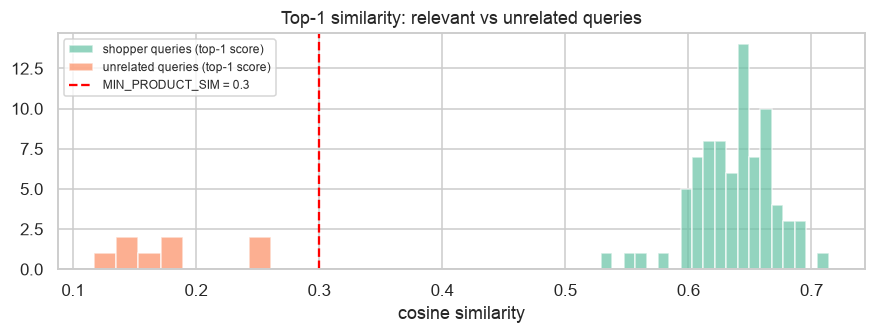

relevant: min 0.53 / median 0.64 | unrelated: max 0.26


In [5]:
# similarity of relevant queries vs. unrelated queries -> justifies the minimum-similarity threshold
rel = [idx.search(q, k=1)[0]["score"] for q in sample.customer_query.head(80)]
unrel_q = ["What is the capital of France?", "Best laptop for gaming", "How do I bake bread?", "Cheap flights to Goa",
           "Python list comprehension", "Tell me a joke", "Which phone has the best camera", "Book a doctor appointment"]
unrel = [idx.search(q, k=1)[0]["score"] for q in unrel_q]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(rel, bins=20, alpha=.7, label="shopper queries (top-1 score)"); ax.hist(unrel, bins=8, alpha=.7, label="unrelated queries (top-1 score)")
ax.axvline(config.MIN_PRODUCT_SIM, c="r", ls="--", label=f"MIN_PRODUCT_SIM = {config.MIN_PRODUCT_SIM}")
ax.set_xlabel("cosine similarity"); ax.legend(fontsize=8); ax.set_title("Top-1 similarity: relevant vs unrelated queries")
plt.tight_layout(); plt.savefig(OUT / "03_similarity_threshold.png"); plt.show()
print(f"relevant: min {min(rel):.2f} / median {np.median(rel):.2f} | unrelated: max {max(unrel):.2f}")

Shopper queries score clearly higher than unrelated text. The threshold `MIN_PRODUCT_SIM` (red line) sits between the two groups, so off-topic requests produce "no good match" instead of random products. In the full assistant, off-topic requests are mostly stopped earlier by the controller's guardrail, so this threshold is a second line of defence.

## 3. Constraint parsing: explicit, inspectable rules

In [6]:
from src.recommender import parse_constraints, recommend, validate, SYSTEM
for q in ["Recommend casual sneakers under ₹4000 for daily wear.", "Suggest products for a premium customer who prefers black formal shoes.",
          "Need a waterproof jacket for winter travel", "Show me a Fossil watch below 5000", "Grey jeans for office above Rs 1000"]:
    print(f"{q!r:75} -> {parse_constraints(q)}")

'Recommend casual sneakers under ₹4000 for daily wear.'                     -> {'max_price': 4000.0, 'sub_category': ['Sneakers']}
'Suggest products for a premium customer who prefers black formal shoes.'   -> {'sub_category': ['Formal'], 'color': ['Black'], 'premium': True}
'Need a waterproof jacket for winter travel'                                -> {'sub_category': ['Jacket']}
'Show me a Fossil watch below 5000'                                         -> {'max_price': 5000.0, 'sub_category': ['Watch']}
'Grey jeans for office above Rs 1000'                                       -> {'min_price': 1000.0, 'sub_category': ['Jeans'], 'color': ['Grey']}


## 4. Grounded recommendations with structured output

The prompt:

In [7]:
print(SYSTEM)

You are a retail shopping assistant. Recommend products ONLY from the CANDIDATES list.
Rules:
- Use only facts present in the candidate text (price, brand, colour, rating, use case, review). Never invent products or facts.
- Recommend at most 3 items that best fit the shopper's request; respect any budget.
- Every recommended item must be referenced by its exact item_id.
- If no candidate fits, return an empty list and say so in the explanation.
Return JSON only:
{"recommended_products": [{"item_id": "...", "title": "...", "price": 0, "why": "one sentence grounded in the candidate text"}],
 "explanation": "2-3 sentences summarising why these fit", "supporting_ids": ["..."]}


In [8]:
def show(res):
    print("QUERY:", res["query"]); print("status:", res["status"], "| constraints applied:", res["constraints"]["applied"])
    print("trace:"); [print("   ", t) for t in res["trace"]]
    print("retrieved:"); print(pd.DataFrame(res["retrieved"]).to_string(index=False))
    print("\nSTRUCTURED OUTPUT:")
    print(json.dumps({k: res.get(k) for k in ["recommended_products", "explanation", "supporting_ids"]}, indent=1, ensure_ascii=False))
    print("=" * 110)
r1 = recommend("Recommend casual sneakers under ₹4000 for daily wear."); show(r1)

QUERY: Recommend casual sneakers under ₹4000 for daily wear.
status: ok | constraints applied: {'max_price': 4000.0, 'sub_category': ['Sneakers']}
trace:
    constraints parsed: {"max_price": 4000.0, "sub_category": ["Sneakers"]}
    retrieved 5 items (min similarity 0.3): ITM0845(0.54), ITM0905(0.54), ITM0851(0.53), ITM0565(0.53), ITM0282(0.53)
    validation: all recommended items grounded and within budget
retrieved:
item_id  score                                   title   price  rating
ITM0845 0.5407 Skechers Black Sneakers Synthetic Shoes 2745.26     3.0
ITM0905 0.5403   Adidas Black Sneakers Synthetic Shoes 2414.26     4.3
ITM0851 0.5274           Nike Grey Sneakers Mesh Shoes 1918.90     4.1
ITM0565 0.5270     Adidas Black Sneakers Leather Shoes 1327.31     4.5
ITM0282 0.5255    Adidas Blue Sneakers Synthetic Shoes 2102.36     4.2

STRUCTURED OUTPUT:
{
 "recommended_products": [
  {
   "item_id": "ITM0845",
   "title": "Skechers Black Sneakers Synthetic Shoes",
   "price": 2745.

In [9]:
show(recommend("Suggest products for a premium customer who prefers black formal shoes."))
show(recommend("Need a warm jacket for winter travel under 3000"))

QUERY: Suggest products for a premium customer who prefers black formal shoes.
status: ok | constraints applied: {'sub_category': ['Formal'], 'color': ['Black'], 'premium': True}
trace:
    constraints parsed: {"sub_category": ["Formal"], "color": ["Black"], "premium": true}
    premium intent -> boosted Premium price band and higher-rated items
    retrieved 5 items (min similarity 0.3): ITM1341(0.59), ITM0621(0.58), ITM1288(0.60), ITM1155(0.55), ITM0656(0.56)
    validation: all recommended items grounded and within budget
retrieved:
item_id  score                             title   price  rating
ITM1341 0.5908 Bata Black Formal Synthetic Shoes 3849.75     3.9
ITM0621 0.5770   Puma Black Formal Leather Shoes 5752.03     4.5
ITM1288 0.5995 Adidas Black Formal Leather Shoes 3185.94     5.0
ITM1155 0.5533      Nike Black Formal Mesh Shoes 3249.58     5.0
ITM0656 0.5622 Bata Black Formal Synthetic Shoes 3384.61     4.4

STRUCTURED OUTPUT:
{
 "recommended_products": [
  {
   "item_id": "

## 5. Weak / empty retrieval is handled gracefully

In [10]:
show(recommend("Recommend a red watch under ₹300."))       # budget too low for any red watch
r = recommend("I want a purple silk saree under 2000")    # nothing like this in the catalogue
print(r["status"], "|", r.get("explanation"), "|", r["trace"])

QUERY: Recommend a red watch under ₹300.
status: weak_match | constraints applied: {'max_price': 300.0}
trace:
    constraints parsed: {"max_price": 300.0, "sub_category": ["Watch"], "color": ["Red"]}
    no items matched all constraints -> relaxed 'color'
    no items matched all constraints -> relaxed 'sub_category'
    retrieved 4 items (min similarity 0.3): ITM1317(0.36), ITM0671(0.33), ITM1423(0.32), ITM0520(0.31)
    validation: LLM returned no valid grounded item -> fell back to top retrieved items
retrieved:
item_id  score                                         title  price  rating
ITM1317 0.3604     Wildcraft Blue Wallet Leather Accessories  299.4     3.6
ITM0671 0.3294             Titan Grey Cap Fabric Accessories  299.4     3.8
ITM1423 0.3233              Nike Blue Sneakers Leather Shoes  299.4     4.1
ITM0520 0.3060 Wildcraft Grey Backpack Synthetic Accessories  299.4     5.0

STRUCTURED OUTPUT:
{
 "recommended_products": [
  {
   "item_id": "ITM1317",
   "title": "Wildcra

- When no item meets all the constraints, the system **relaxes colour, then brand, then sub-category**, and says so in the trace.
- If nothing fits even then (for example the budget is below every price), it returns `status = no_match` with a clear explanation. It does not recommend an item that breaks the budget.

## 6. The grounding validator

As a test, an answer containing an invented product and an over-budget item is passed to the validator:

In [11]:
hits = [{"doc_id": x["item_id"], "meta": {"final_price": x["price"], "product_title": x["title"]}} for x in r1["retrieved"]]
fake = {"recommended_products": [{"item_id": r1["retrieved"][0]["item_id"], "title": "x", "price": 1, "why": "ok"},
                                 {"item_id": "ITM9999", "title": "Invented shoe", "price": 999, "why": "hallucinated"}]}
checked, issues = validate(fake, hits, {"max_price": 4000})
print("kept:", [p["item_id"] for p in checked["recommended_products"]], "| issues:", issues)
print("\nAPI usage so far:", USAGE)

kept: ['ITM0845'] | issues: ['dropped ITM9999: not in retrieved context']

API usage so far: {'llm_calls': 0, 'cached_calls': 5, 'prompt_tokens': 0, 'completion_tokens': 0, 'embedding_tokens': 0}


The invented id is removed, and the kept item's price is overwritten with the catalogue price, never the LLM's. **Only retrieved, in-budget items can reach the user.**